# TP Pandas de LI Ziheng Eric et BORNERT Mathilde

Vous pouvez faire des cellules de type Markdown pour écrire du texte.
En mettant des # vous pouvez créer des titres et sous titre

## Todo:
* Télécharger un dataset sur data.gouv.fr
* Le référencer via son lien
* Etudier ce dataset sur pandas
* Garder les output des cellules
* Vérifier que toutes les cellules marchent
* Avant de rendre, faire Kernel -> Restart Kernel and run all cells
* Faire l'évaluation du cours

In [111]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

-> Source du dataset https://www.data.gouv.fr/datasets/prix-des-controles-techniques

In [112]:
df = pd.read_csv('/Users/zeric/cours-info/Hadbn/PandasTP/prix-controle-technique.csv', sep=";")
df = df.set_index('﻿cct_siret')

df = df[['code_departement', 'cat_vehicule_id', 'cat_energie_id', 'prix_visite', 'date_application_visite']]

df.head(10)


/var/folders/2p/r_22wfr57c302hbj5d6_pq8h0000gn/T/ipykernel_2496/4099538999.py:1: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/Users/zeric/cours-info/Hadbn/PandasTP/prix-controle-technique.csv', sep=";")


,code_departement,cat_vehicule_id,cat_energie_id,prix_visite,date_application_visite
﻿cct_siret,,,,,
98525263400011,1,6,6,72.0,2026-04-22
51868567200033,22,6,6,55.0,2026-03-12
98533764100015,21,6,6,45.0,2026-08-17
98525263400011,1,7,6,72.0,2026-04-22
51868567200033,22,7,6,55.0,2026-03-12
98533764100015,21,7,6,65.0,2026-08-17
98525263400011,1,8,6,72.0,2026-04-22
51868567200033,22,8,6,55.0,2026-03-12
98533764100015,21,8,6,75.0,2026-08-17


In [113]:
#Moyenne des prix par département et par catégorie de véhicule

df.groupby(['code_departement', 'cat_vehicule_id'])['prix_visite'].mean()

code_departement  cat_vehicule_id
1                 1                  90.860000
                  2                  93.244186
                  3                  90.044304
                  4                  93.338279
                  5                  94.277108
                                       ...    
45                6                  56.333333
                  7                  59.666667
                  8                  61.333333
                  9                  61.333333
                  10                 61.333333
Name: prix_visite, Length: 1015, dtype: float64

In [114]:
#Nombre de consultations par garage et par catégorie d'énergie
df = pd.read_csv('/Users/zeric/cours-info/Hadbn/PandasTP/prix-controle-technique.csv', sep=";")
#Pour reset l'index en indice naturel, c'est le plus rapide... C'est moche mais it is what it is


df.groupby(['cat_energie_id'])['﻿cct_siret'].value_counts()

/var/folders/2p/r_22wfr57c302hbj5d6_pq8h0000gn/T/ipykernel_2496/2347250041.py:2: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/Users/zeric/cours-info/Hadbn/PandasTP/prix-controle-technique.csv', sep=";")


cat_energie_id  ﻿cct_siret    
1               4695008500038     5
                10021150700015    5
                10500795900015    5
                10657173000014    5
                30163918300047    5
                                 ..
6               94222215900017    3
                94889769900039    3
                94889769900047    3
                43199259300027    2
                94103720200012    2
Name: count, Length: 30230, dtype: int64

Année
2017.0    75.000000
2018.0    88.000000
2019.0    74.107843
2020.0    84.413462
2021.0    83.208538
2022.0    83.284767
2023.0    86.383284
2024.0    85.911751
2025.0    87.087614
2026.0    87.763368
Name: prix_visite, dtype: float64
[2026. 2020. 2021. 2025. 2023. 2024. 2022. 2018. 2019. 2017.]


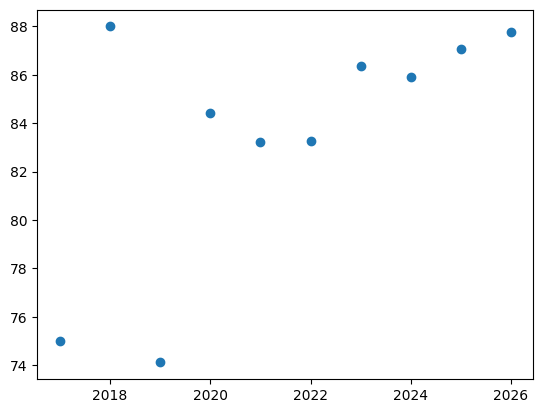

In [ ]:
#Evolution du prix moyen des visite au cour des années

df['date_application_visite'] = pd.to_datetime(df['date_application_visite'])

df['Année'] = df['date_application_visite'].dt.year

Moyenne_année = df.groupby(['Année'])['prix_visite'].mean()

print(Moyenne_année)

les_années = pd.unique(df['Année'])
les_années = les_années[~np.isnan(les_années)]
les_années.sort()
les_moyennes = Moyenne_année.to_numpy()




plt.scatter(les_années, les_moyennes)
